# 20 · Quan hệ với target, tương tác và độ ổn định

**Câu hỏi:** nhóm nào có tỷ lệ mua cao, đủ quy mô và ổn định qua tháng? Dùng 100.224 khách × 10 cutoff 02–11/2022, cùng cohort H1/H2/H3. Đọc các thẻ phân khúc đã dựng lại ở notebook 18. Hai bảng tương tác cuối đọc từ phân tích target-focused hiện có và được ghi rõ nguồn.

Tất cả là EDA mô tả. Lift = tỷ lệ nhóm / tỷ lệ nền cùng cohort hoặc cùng tháng. Các quan sát lặp khách, nên chưa coi là các dòng độc lập để tính CI hay p-value.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'data/MBD-mini').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/MBD-mini').exists(), 'Mở notebook trong thư mục dự án'
AUDIT = ROOT / 'outputs/eda_insights_20261119'
TARGET = ROOT / 'outputs/target_focused_moscow_20261119'
FIG = ROOT / 'outputs/eda_insights_20261119/charts'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'figure.dpi':120,
    'axes.spines.top':False, 'axes.spines.right':False, 'axes.titlesize':13})
def save_chart(fig, name):
    fig.tight_layout()
    for ext in ('png','svg'):
        fig.savefig(FIG / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def read_audit(name):
    return pd.read_csv(AUDIT / name)


In [2]:
cards=read_audit('segment_cards.csv')
monthly=read_audit('monthly_segment_cards.csv')
monthly['month']=pd.to_datetime(monthly.month)
h1=cards[cards.horizon==1].copy()
assert monthly.groupby(['feature','month','horizon']).n.sum().eq(100224).all()
display(h1)

,feature,group,horizon,n,buyers,min_monthly_lift,max_monthly_lift,rate,population_share,buyer_share,lift
0,dialog_recent,False,1,944566,8984,0.754543,0.913178,0.009511,0.942455,0.786690,0.834724
3,dialog_recent,True,1,57674,2436,3.315107,5.136089,0.042237,0.057545,0.213310,3.706831
6,source_count,0,1,32792,316,0.392966,3.455393,0.009636,0.032719,0.027671,0.845717
9,source_count,1,1,250770,1605,0.455733,0.668068,0.006400,0.250210,0.140543,0.561701
12,source_count,2,1,463500,4456,0.667420,0.953365,0.009614,0.462464,0.390193,0.843725
15,source_count,3,1,255178,5043,1.555180,2.113103,0.019763,0.254608,0.441594,1.734408
18,trx_band,0,1,84670,1190,0.546615,3.409510,0.014055,0.084481,0.104203,1.233454
21,trx_band,1-9,1,101092,770,0.446182,0.873742,0.007617,0.100866,0.067426,0.668466
24,trx_band,10-99,1,296569,1740,0.451989,0.611112,0.005867,0.295906,0.152364,0.514907
27,trx_band,100+,1,519909,7720,1.167933,1.559289,0.014849,0.518747,0.676007,1.303154


## Tỷ lệ mua theo feature
Quan hệ TRX có thể phi tuyến. Nhóm không có log được giữ riêng; không đánh đồng với khách mới hoặc không hoạt động.

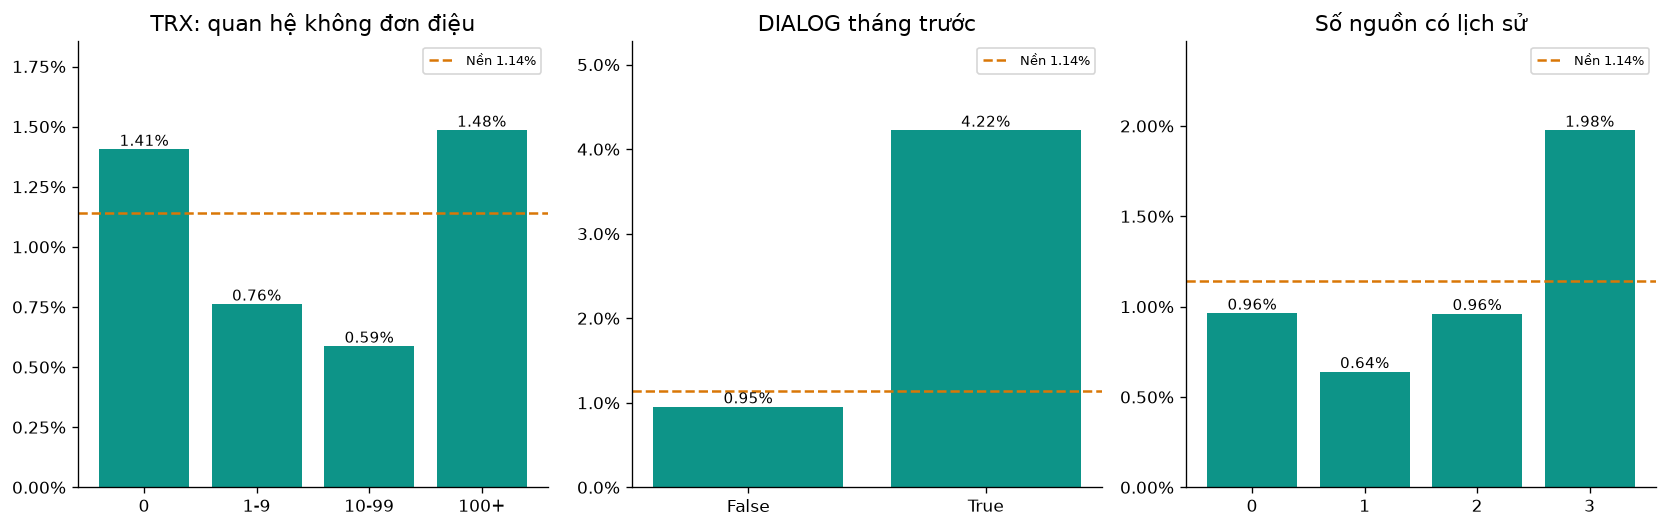

In [3]:
fig,axes=plt.subplots(1,3,figsize=(14,4.5))
baseline=h1[h1.feature=='trx_band'].buyers.sum()/h1[h1.feature=='trx_band'].n.sum()
for ax,feature,title in zip(axes,['trx_band','dialog_recent','source_count'],['TRX: quan hệ không đơn điệu','DIALOG tháng trước','Số nguồn có lịch sử']):
    a=h1[h1.feature==feature]
    ax.bar(a.group.astype(str),a.rate,color='#0d9488')
    ax.axhline(baseline,color='#d97706',ls='--',label=f'Nền {baseline:.2%}')
    for i,r in enumerate(a.itertuples()): ax.text(i,r.rate,f'{r.rate:.2%}',ha='center',va='bottom',fontsize=9)
    ax.set_ylim(0,a.rate.max()*1.25); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_title(title); ax.legend(fontsize=8)
save_chart(fig,'20_feature_target_rates')

## Quy mô và đóng góp người mua
Tỷ trọng người mua là phần khách–tháng dương nằm trong nhóm; đây chưa phải recall trên dữ liệu kiểm chứng ngoài thời gian.

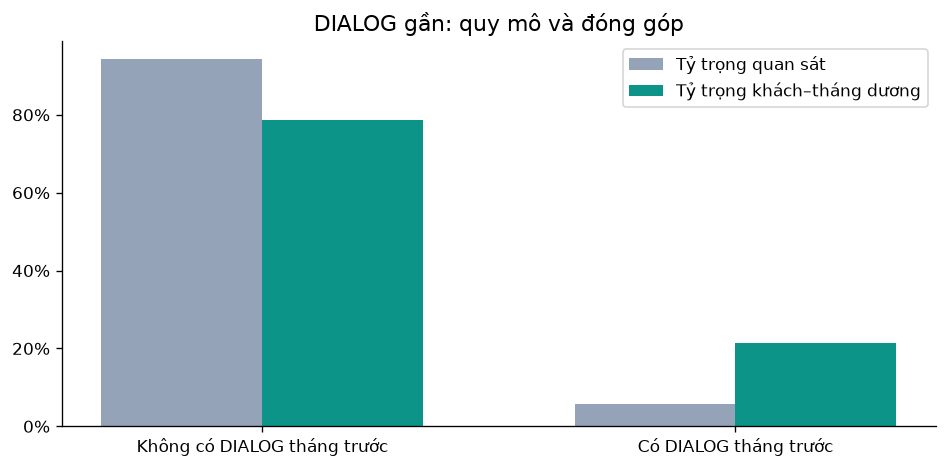

In [4]:
a=h1[h1.feature=='dialog_recent']; x=np.arange(len(a))
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(x-.17,a.population_share,width=.34,label='Tỷ trọng quan sát',color='#94a3b8')
ax.bar(x+.17,a.buyer_share,width=.34,label='Tỷ trọng khách–tháng dương',color='#0d9488')
ax.set_xticks(x,['Không có DIALOG tháng trước','Có DIALOG tháng trước'])
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_title('DIALOG gần: quy mô và đóng góp'); ax.legend()
save_chart(fig,'20_dialog_contribution')

## Lift theo tháng: tránh kết luận từ tỷ lệ gộp
Đường nền 1× là tỷ lệ mua của toàn bộ khách trong cùng tháng. Kiểm tra xem nhóm có giữ cùng hướng quan hệ qua mọi cutoff không.

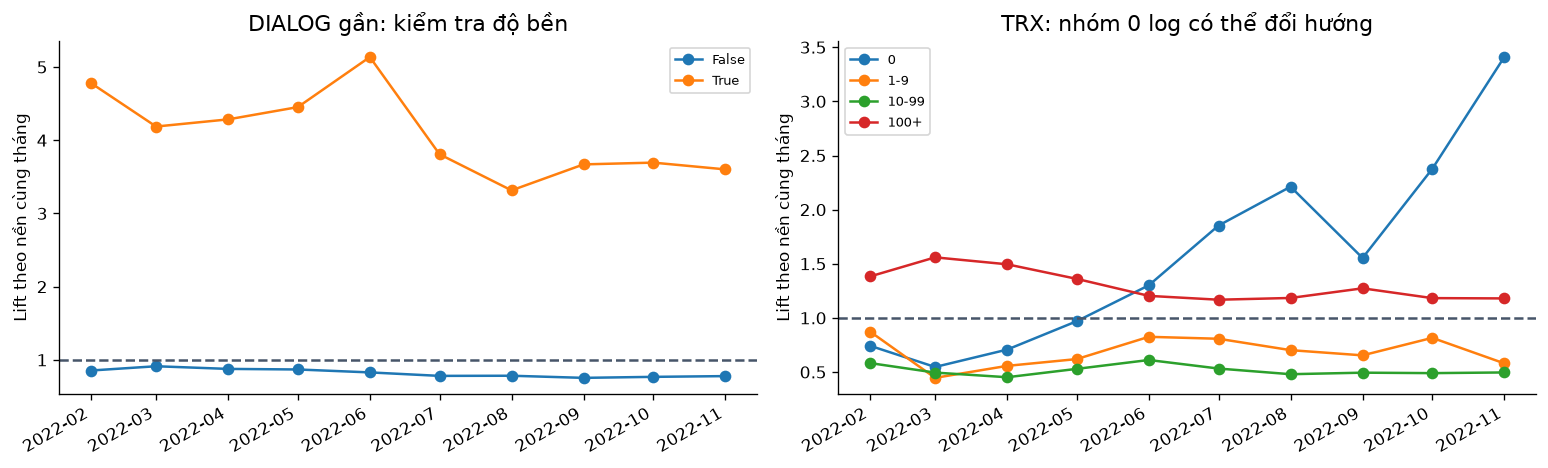

,feature,group,min_monthly_lift,max_monthly_lift
0,dialog_recent,False,0.754543,0.913178
3,dialog_recent,True,3.315107,5.136089
6,source_count,0,0.392966,3.455393
9,source_count,1,0.455733,0.668068
12,source_count,2,0.667420,0.953365
15,source_count,3,1.555180,2.113103
18,trx_band,0,0.546615,3.409510
21,trx_band,1-9,0.446182,0.873742
24,trx_band,10-99,0.451989,0.611112
27,trx_band,100+,1.167933,1.559289


In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,feature,title in zip(axes,['dialog_recent','trx_band'],['DIALOG gần: kiểm tra độ bền','TRX: nhóm 0 log có thể đổi hướng']):
    a=monthly[(monthly.feature==feature)&(monthly.horizon==1)]
    for group,z in a.groupby('group'):
        ax.plot(z.month,z.lift,marker='o',label=str(group))
    ax.axhline(1,ls='--',color='#475569'); ax.set_title(title); ax.set_ylabel('Lift theo nền cùng tháng'); ax.legend(fontsize=8)
fig.autofmt_xdate(); save_chart(fig,'20_monthly_lift')
display(h1[['feature','group','min_monthly_lift','max_monthly_lift']])

**Insight:** DIALOG gần giữ lift cao ở mọi cutoff; nhóm không có TRX dao động từ dưới nền sang trên nền. Cần kiểm tra cơ cấu cohort và thời gian quan sát trước khi dùng nhóm 0 TRX làm quy tắc.

## H1/H2/H3 trên cùng cohort
Horizon dài hơn có nhiều cơ hội ghi nhận nhãn dương hơn. Tỷ lệ tăng chưa chứng minh khả năng xếp hạng tốt hơn.

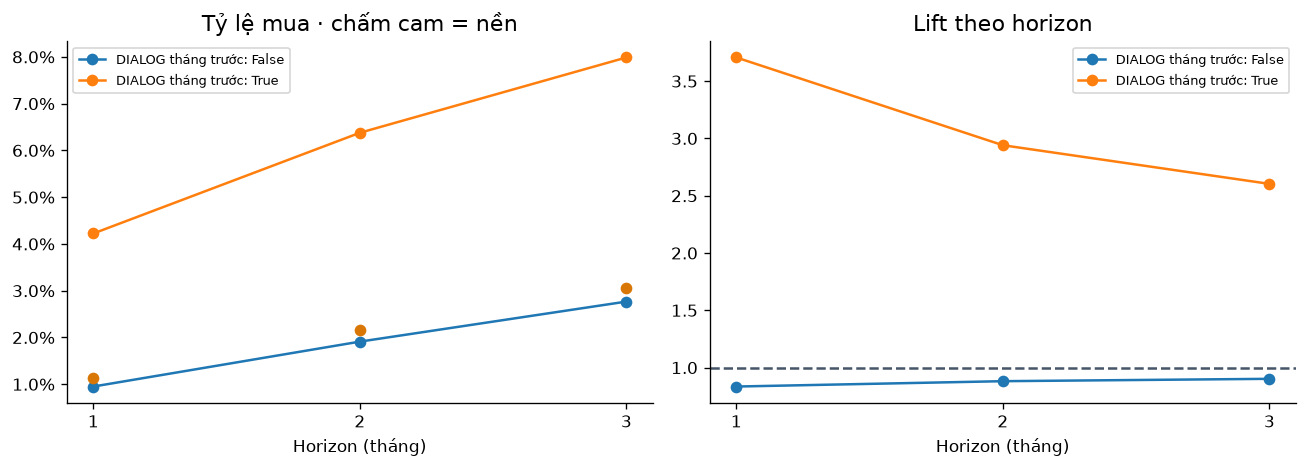

In [6]:
a=cards[cards.feature=='dialog_recent']
fig,axes=plt.subplots(1,2,figsize=(11,4))
for group,z in a.groupby('group'):
    for ax,col in zip(axes,['rate','lift']): ax.plot(z.horizon,z[col],marker='o',label=f'DIALOG tháng trước: {group}')
for h in (1,2,3):
    z=a[a.horizon==h]; axes[0].scatter(h,z.buyers.sum()/z.n.sum(),color='#d97706',zorder=3)
axes[0].yaxis.set_major_formatter(PercentFormatter(1)); axes[0].set_title('Tỷ lệ mua · chấm cam = nền')
axes[1].set_title('Lift theo horizon'); axes[1].axhline(1,ls='--',color='#475569')
for ax in axes: ax.set_xticks([1,2,3]); ax.set_xlabel('Horizon (tháng)'); ax.legend(fontsize=8)
save_chart(fig,'20_horizon_comparison')

## Tương tác TRX × DIALOG
Nguồn tái sử dụng: `outputs/target_focused_moscow_20261119/dialog_by_trx_state.csv`. Các ô cộng đủ cohort; bảng phân tầng không loại trừ toàn bộ yếu tố nhiễu.

,trx_state,dialog_recent,n,buyers_h1,rate_h1
0,active previous month,False,716992,7753,0.010813
1,active previous month,True,51918,2103,0.040506
2,no history,False,81780,918,0.011225
3,no history,True,2890,272,0.094118
4,older history,False,145794,313,0.002147
5,older history,True,2866,61,0.021284


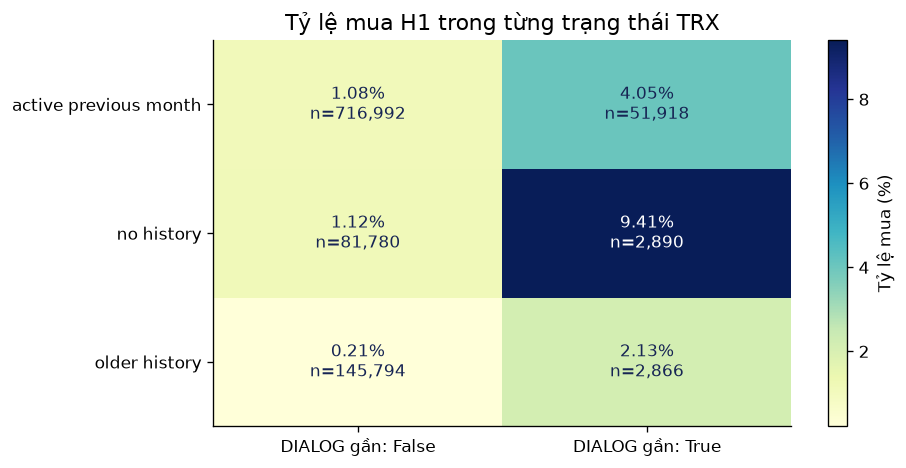

In [7]:
interaction=pd.read_csv(TARGET/'dialog_by_trx_state.csv')
assert interaction.n.sum()==100224*10
display(interaction[['trx_state','dialog_recent','n','buyers_h1','rate_h1']])
p=interaction.pivot(index='trx_state',columns='dialog_recent',values='rate_h1')
counts=interaction.pivot(index='trx_state',columns='dialog_recent',values='n')
fig,ax=plt.subplots(figsize=(8,4)); im=ax.imshow(p.to_numpy()*100,cmap='YlGnBu',aspect='auto')
for i in range(len(p)):
    for j in range(len(p.columns)):
        v=p.iloc[i,j]; ax.text(j,i,f'{v:.2%}\nn={counts.iloc[i,j]:,}',ha='center',va='center',color='white' if v>.06 else '#172554')
ax.set_xticks(range(len(p.columns)),[f'DIALOG gần: {v}' for v in p.columns]); ax.set_yticks(range(len(p)),p.index)
ax.set_title('Tỷ lệ mua H1 trong từng trạng thái TRX'); fig.colorbar(im,ax=ax,label='Tỷ lệ mua (%)')
save_chart(fig,'20_trx_dialog_interaction')

## Lịch sử mua quan sát được
Nguồn tái sử dụng: `dialog_by_prior_purchase.csv`. “Chưa có mua quan sát được” chỉ nói về phần nhãn từ 02/2022; không khẳng định chưa từng mua. Prior-purchase feature chỉ được dùng khi nhãn quá khứ thực sự sẵn có trước cutoff.

,prior_purchase_state,dialog_recent,n,buyers_h1,rate_h1
0,no observed prior purchase,False,809328,6754,0.008345
1,no observed prior purchase,True,43331,1675,0.038656
2,observed prior purchase,False,38720,1373,0.035460
3,observed prior purchase,True,10637,577,0.054245
4,unknown before label start,False,96518,857,0.008879
5,unknown before label start,True,3706,184,0.049649


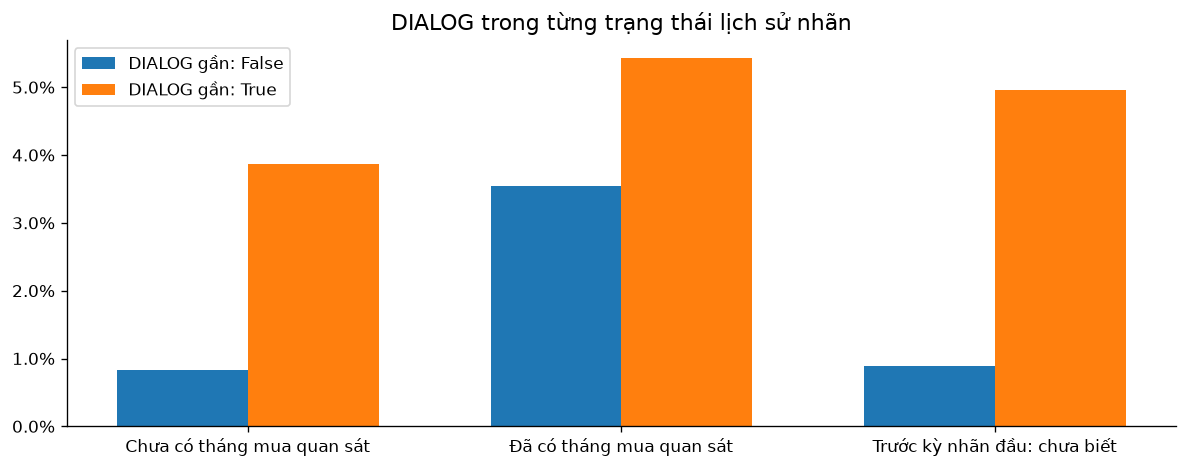

In [8]:
prior=pd.read_csv(TARGET/'dialog_by_prior_purchase.csv')
assert prior.n.sum()==100224*10
display(prior[['prior_purchase_state','dialog_recent','n','buyers_h1','rate_h1']])
p=prior.pivot(index='prior_purchase_state',columns='dialog_recent',values='rate_h1')
fig,ax=plt.subplots(figsize=(10,4)); x=np.arange(len(p))
for j,col in enumerate(p.columns): ax.bar(x+(j-.5)*.35,p[col],width=.35,label=f'DIALOG gần: {col}')
ax.set_xticks(x,['Chưa có tháng mua quan sát','Đã có tháng mua quan sát','Trước kỳ nhãn đầu: chưa biết'])
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_title('DIALOG trong từng trạng thái lịch sử nhãn'); ax.legend()
save_chart(fig,'20_prior_purchase_interaction')

## Kết luận và checklist tiếp theo

Ưu tiên kiểm tra DIALOG recency/presence, TRX phi tuyến, masks đa nguồn và tương tác DIALOG×TRX. Nhóm không TRX nhưng DIALOG gần cần đối chiếu cơ chế ghi nhận dữ liệu.

- [x] So nhóm và horizon với mẫu số nhất quán; báo quy mô và đóng góp.
- [x] Kiểm tra lift theo 10 tháng, không chỉ tỷ lệ gộp.
- [ ] Bootstrap theo khách để báo CI, giữ nguyên chuỗi tháng của mỗi khách.
- [ ] Kiểm soát đồng thời history age, prior purchase và coverage; kiểm tra Simpson's paradox.
- [ ] Fit ngưỡng trên tháng train; kiểm chứng ngoài thời gian với cùng top-K.
- [ ] Xác minh độ trễ nhãn, drift và giá trị bổ sung từng nguồn bằng ablation.

Chưa có bằng chứng nhân quả, cải thiện mô hình hoặc hiệu quả chiến dịch từ các biểu đồ này. [Sổ insight và checklist đầy đủ](../docs/eda_insights_checklist_20261119.md).